# Dimensionality and sparseness

The two functions live in `utils/population_metrics.py'.
This notebook loads data, calls them, and plots.

**Convention:** `X` is **(time bins × neurons)** — rows are time, columns are
neurons. 

In [146]:
import os, pickle
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
%matplotlib inline

%load_ext autoreload
%autoreload 2

from utils import rates_matrix, compute_pca, compute_sparseness

DATA_DIR = "../data/spike_time_dicts"
SESSION  = "buzsaki_Achilles_10252013"
BIN_SIZE = 1.0          # s
FIG_DIR  = "../figures"


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## 1. Load spike times, build X

In [147]:
with open(os.path.join(DATA_DIR, f"{SESSION}.pkl"), "rb") as f:
    spike_time_dict = pickle.load(f)

X, neuron_ids, edges = rates_matrix(spike_time_dict, bin_size=BIN_SIZE)

print(f"X: {X.shape[0]:,} bins x {X.shape[1]} neurons "
      f"({X.shape[0]*BIN_SIZE/60:.0f} min, {X.sum():,.0f} spikes)")

X: 34,862 bins x 137 neurons (581 min, 8,414,607 spikes)


RASTERPLOT

window t0 = 732.0 s | mean s_t in window 0.336 | session mean 0.336 | scanned 34,858 windows


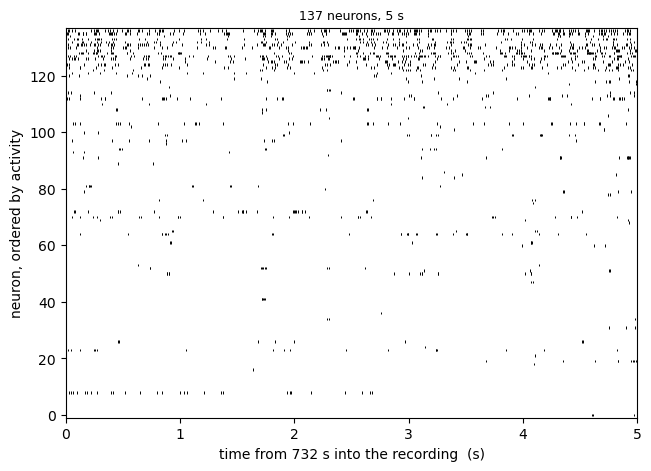

In [148]:
s    = (X > 0).mean(axis=1)                   # fraction active per bin
W    = int(5.0 / BIN_SIZE)
mw   = np.convolve(s, np.ones(W) / W, mode="valid")
best = np.argmin(np.abs(mw - s.mean()))
t0, win = best * BIN_SIZE, 5.0
print(f"window t0 = {t0:.1f} s | mean s_t in window {mw[best]:.3f} "
      f"| session mean {s.mean():.3f} | scanned {len(mw):,} windows")                                 
order   = np.argsort((X > 0).mean(axis=0))              # quietest at bottom, busiest at top (over_neuron)

rows = [spike_time_dict[neuron_ids[j]][(spike_time_dict[neuron_ids[j]] >= t0) &
                                       (spike_time_dict[neuron_ids[j]] <  t0 + win)] - t0
        for j in order]

fig, ax = plt.subplots(figsize=(6.4, 4.6), constrained_layout=True)
ax.eventplot(rows, colors="k", lineoffsets=np.arange(len(rows)),
             linelengths=0.9, linewidths=0.7)
ax.set_xlim(0, win)
ax.set_ylim(-1, len(rows))
ax.set_xlabel(f"time from {t0:.0f} s into the recording  (s)")
ax.set_ylabel("neuron, ordered by activity")
ax.set_title(f"{X.shape[1]} neurons, {win:.0f} s", fontsize=9)

fig.savefig(os.path.join(FIG_DIR, "raster.png"), dpi=300, bbox_inches="tight")
plt.show()

## 2. `compute_pca(X)`

Returns `(eigvals, alpha)`: the descending eigenvalue spectrum, and the
exponent $\alpha$ in $\lambda_n \propto n^{-\alpha}$.


In [161]:
eigvals, alpha = compute_pca(X, zscore=False)  

exp_var  = eigvals / eigvals.sum()                    # variance fraction per PC
pr   = eigvals.sum()**2 / (eigvals**2).sum()          # participation ratio,the average number of PCs that contribute to the variance of the data
pc1_pct = exp_var[0] * 100                            # PC1 variance percentage

print(f"alpha   = {alpha:.3f}")
print(f"PR      = {pr:.1f} of {X.shape[1]} neurons")
print(f"PC1     = {pc1_pct:.1f}% of variance")


alpha   = 1.289
PR      = 6.4 of 137 neurons
PC1     = 35.8% of variance


### Scree plot

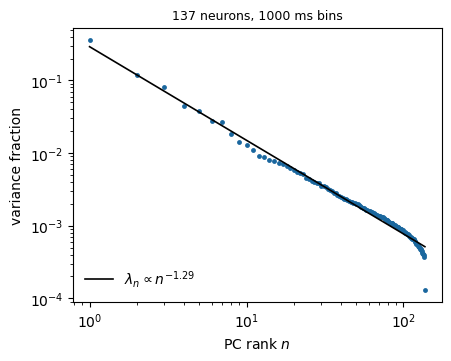

In [150]:
n   = np.arange(1, len(exp_var) + 1)                                                # PC rank
fit = 10**(np.mean(np.log10(exp_var)) + alpha*np.mean(np.log10(n))) * n**(-alpha)   #height, best fit line through the data

fig, ax = plt.subplots(figsize=(4.4, 3.5), constrained_layout=True)
ax.loglog(n, exp_var, "o", ms=3.5, mfc="#1a679e", mec="none")
ax.loglog(n, fit, "k-", lw=1.2, label=rf"$\lambda_n \propto n^{{-{alpha:.2f}}}$")
ax.set_xlabel("PC rank $n$")
ax.set_ylabel("variance fraction")
ax.set_title(f"{X.shape[1]} neurons, {BIN_SIZE*1000:.0f} ms bins", fontsize=9)
ax.legend(frameon=False, loc="lower left")
fig.savefig("../figures/scree.png", dpi=300)
plt.show()


## 3. `compute_sparseness(X)`

Returns `(over_time, over_neurons)`:

- `over_time[t]` — fraction of neurons active in bin *t*
- `over_neurons[i]` — fraction of bins in which neuron *i* is active

In [151]:
over_time, over_neurons = compute_sparseness(X)

print(f"mean active fraction per bin : {over_time.mean():.3f} "
      f"({over_time.mean()*X.shape[1]:.1f} of {X.shape[1]} neurons)")
print(f"fully silent bins            : {np.mean(over_time == 0):.3%}")

mean active fraction per bin : 0.336 (46.0 of 137 neurons)
fully silent bins            : 0.000%


SPARSENESS OVER TIME

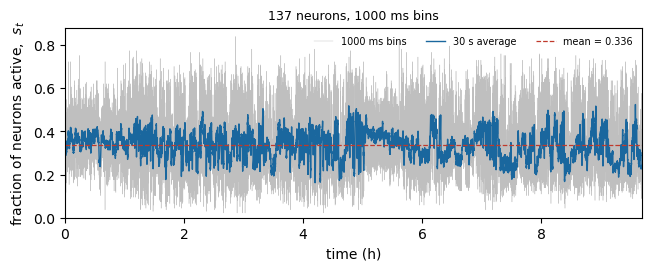

In [152]:
t    = np.arange(len(over_time)) * BIN_SIZE / 3600     # bin index -> hours
w    = int(30 / BIN_SIZE)                              # Smooths out the noisy, fast-jumping raw data by taking a rolling 30-second average
sm   = np.convolve(over_time, np.ones(w) / w, mode="valid")
t_sm = t[w//2 : w//2 + len(sm)]                        # aligns the time axis so the smoothed line matches up correctly with the central timestamps of that rolling window

fig, ax = plt.subplots(figsize=(6.4, 2.6), constrained_layout=True)
ax.plot(t, over_time, lw=0.3, color="0.75", rasterized=True,
        label=f"{BIN_SIZE*1000:.0f} ms bins")
ax.plot(t_sm, sm, lw=1.0, color="#1a679e", label="30 s average")
ax.axhline(over_time.mean(), color="#c0392b", lw=0.9, ls="--",
           label=f"mean = {over_time.mean():.3f}")
ax.set_xlim(0, t[-1])
ax.set_ylim(0, None)
ax.set_xlabel("time (h)")
ax.set_ylabel("fraction of neurons active,  $s_t$")
ax.set_title(f"{X.shape[1]} neurons, {BIN_SIZE*1000:.0f} ms bins", fontsize=9)
ax.legend(frameon=False, fontsize=7, ncol=3, loc="upper right")

fig.savefig(os.path.join(FIG_DIR, "sparseness_over_time.png"), dpi=300, bbox_inches="tight")
plt.show()

s_t  mean 0.3356  median 0.3212 


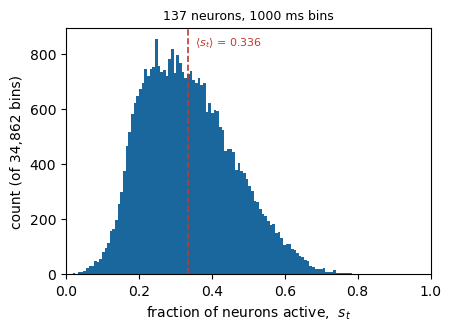

In [153]:
N    = X.shape[1]
bins = (np.arange(N + 2) - 0.5) / N     #Define bin edges for normalized fractions  

fig, ax = plt.subplots(figsize=(4.4, 3.2), constrained_layout=True)
ax.hist(over_time, bins=bins, color="#1a679e")
ax.axvline(over_time.mean(), color="#c0392b", lw=1.2, ls="--")
ax.annotate(rf"$\langle s_t \rangle$ = {over_time.mean():.3f}",
            (over_time.mean(), 0.97), xycoords=("data", "axes fraction"),
            xytext=(5, 0), textcoords="offset points",
            va="top", fontsize=8, color="#c0392b")
ax.set_xlim(0, 1)
ax.set_xlabel("fraction of neurons active,  $s_t$")
ax.set_ylabel(f"count (of {len(over_time):,} bins)")
ax.set_title(f"{N} neurons, {BIN_SIZE*1000:.0f} ms bins", fontsize=9)

fig.savefig(os.path.join(FIG_DIR, "sparseness_hist_st.png"), dpi=300, bbox_inches="tight")
print(f"s_t  mean {over_time.mean():.4f}  median {np.median(over_time):.4f} ")
plt.show()

SPARSENESS OVER NEURONS

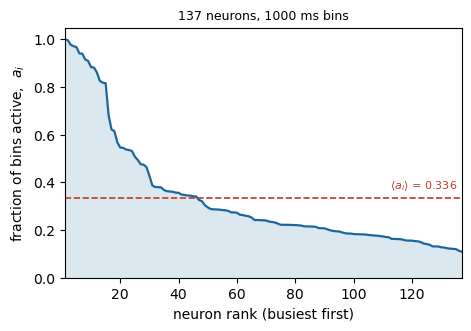

In [154]:
act_sorted = np.sort(over_neurons)[::-1]          # Sort neurons by activity fraction in descending order for a clean curve
index      = np.arange(1, len(act_sorted) + 1)    # index, not neuron identity

fig, ax = plt.subplots(figsize=(4.6, 3.2), constrained_layout=True)
ax.plot(index, act_sorted, "-", lw=1.6, color="#1a679e")
ax.fill_between(index, 0, act_sorted, color="#1a679e", alpha=0.15, lw=0)
ax.axhline(over_neurons.mean(), color="#c0392b", lw=1.2, ls="--")
ax.annotate(rf"$\langle a_i \rangle$ = {over_neurons.mean():.3f}",
            (0.99, over_neurons.mean()), xycoords=("axes fraction", "data"),
            xytext=(0, 4), textcoords="offset points",
            ha="right", va="bottom", fontsize=8, color="#c0392b")
ax.set_xlim(1, len(act_sorted))
ax.set_ylim(0, None)
ax.set_xlabel("neuron rank (busiest first)")
ax.set_ylabel("fraction of bins active,  $a_i$")
ax.set_title(f"{X.shape[1]} neurons, {BIN_SIZE*1000:.0f} ms bins", fontsize=9)

fig.savefig(os.path.join(FIG_DIR, "sparseness_over_neurons_sorted.png"), dpi=300, bbox_inches="tight")
plt.show()

a_i  mean 0.3356  median 0.2409


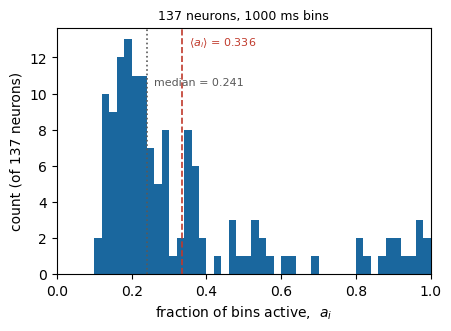

In [155]:
bins = np.linspace(0, 1, 51)                   

fig, ax = plt.subplots(figsize=(4.4, 3.2), constrained_layout=True)
ax.hist(over_neurons, bins=bins, color="#1a679e")
ax.axvline(over_neurons.mean(), color="#c0392b", lw=1.2, ls="--")
ax.annotate(rf"$\langle a_i \rangle$ = {over_neurons.mean():.3f}",
            (over_neurons.mean(), 0.97), xycoords=("data", "axes fraction"),
            xytext=(5, 0), textcoords="offset points",
            va="top", fontsize=8, color="#c0392b")
ax.axvline(np.median(over_neurons), color="0.35", lw=1.2, ls=":")
ax.annotate(f"median = {np.median(over_neurons):.3f}",
            (np.median(over_neurons), 0.80), xycoords=("data", "axes fraction"),
            xytext=(5, 0), textcoords="offset points",
            va="top", fontsize=8, color="0.35")
ax.set_xlim(0, 1)
ax.set_xlabel("fraction of bins active,  $a_i$")
ax.set_ylabel(f"count (of {len(over_neurons)} neurons)")
ax.set_title(f"{X.shape[1]} neurons, {BIN_SIZE*1000:.0f} ms bins", fontsize=9)

fig.savefig(os.path.join(FIG_DIR, "sparseness_hist_ai.png"), dpi=300, bbox_inches="tight")
print(f"a_i  mean {over_neurons.mean():.4f}  median {np.median(over_neurons):.4f}")

plt.show()

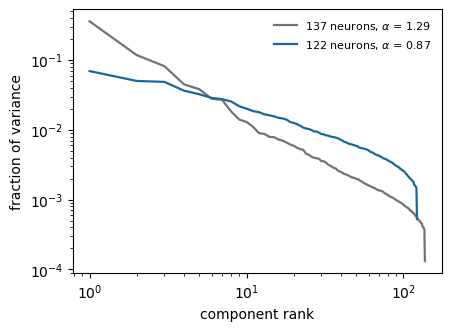

In [160]:
rate = X.sum(axis=0) / (X.shape[0] * BIN_SIZE)        # Hz per neuron; grid duration as denominator

keep = rate < np.sort(rate)[::-1][n_ex - 1]          # 122 retained, same rule as panel d
ev_all, al_all = compute_pca(np.asarray(X, float))
ev_kep, al_kep = compute_pca(np.asarray(X[:, keep], float))

fig, ax = plt.subplots(figsize=(4.4, 3.2), constrained_layout=True)
for ev_, al_, n, c in [(ev_all, al_all, X.shape[1], "0.45"), (ev_kep, al_kep, keep.sum(), "#1a679e")]:
    ax.plot(np.arange(1, len(ev_) + 1), ev_ / ev_.sum(), "-", lw=1.6, color=c,
            label=rf"{n} neurons, $\alpha$ = {al_:.2f}")
ax.set(xscale="log", yscale="log", xlabel="component rank", ylabel="fraction of variance")
ax.legend(frameon=False, fontsize=8)
plt.show()